Importing Libraries

In [ ]:
!pip install transformers datasets accelerate scikit-learn matplotlib seaborn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Importing Libraries

In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    T5ForSequenceClassification,  # Use T5ForSequenceClassification instead
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from tqdm.auto import tqdm

Loading the dataset

In [ ]:
print("Loading dataset...")
dataset = load_dataset("lex_glue", "ecthr_a")
small_train = dataset["train"].shuffle(seed=42).select(range(2500))
dataset_small = {
    "train": small_train,
    "test": dataset["test"].select(range(250))  # Using a small test set for quick evaluation
}
print(f"Train: {len(dataset_small['train'])} examples")
print(f"Test: {len(dataset_small['test'])} examples")


Loading dataset...


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/34.1k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/42.4M [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/5.68M [00:00<?, ?B/s]

validation-00000-of-00001.parquet:   0%|          | 0.00/5.26M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Train: 2500 examples
Test: 250 examples


Importing T5 Model

In [ ]:
model_name = "t5-base"
print(f"Loading {model_name}...")

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = T5ForSequenceClassification.from_pretrained(
    model_name,
    num_labels=10,
    problem_type="multi_label_classification"
)

Loading t5-base...


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/892M [00:00<?, ?B/s]

Some weights of T5ForSequenceClassification were not initialized from the model checkpoint at t5-base and are newly initialized: ['classification_head.dense.bias', 'classification_head.dense.weight', 'classification_head.out_proj.bias', 'classification_head.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Preprocessing Function

In [ ]:
def preprocess_function(examples):
    if isinstance(examples["text"][0], list):
        texts = [" ".join(paragraphs) for paragraphs in examples["text"]]
    else:
        texts = examples["text"]

    # T5 typically expects inputs in the format "task_prefix: text"
    # For classification, we can use a prefix like "classify legal text:"
    prefixed_texts = ["classify legal text: " + text for text in texts]

    tokenized_inputs = tokenizer(
        prefixed_texts,
        truncation=True,
        padding="max_length",
        max_length=512
    )

    if "labels" in examples:
        labels = []
        for label in examples["labels"]:
            if isinstance(label, int):
                one_hot = [0] * 10
                one_hot[label] = 1
                labels.append(one_hot)
            elif isinstance(label, list):
                if all(isinstance(l, int) for l in label):
                    one_hot = [0] * 10
                    for l in label:
                        if 0 <= l < 10:
                            one_hot[l] = 1
                    labels.append(one_hot)
                else:
                    labels.append(label)

        tokenized_inputs["labels"] = labels

    return tokenized_inputs


Applying Preprocessing

In [ ]:
tokenized_dataset = {
    split: dataset_small[split].map(
        preprocess_function,
        batched=True,
        batch_size=32,
        num_proc=2,
        remove_columns=dataset_small[split].column_names
    )
    for split in dataset_small
}

Map (num_proc=2):   0%|          | 0/2500 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/250 [00:00<?, ? examples/s]

Creating Data collector

In [ ]:
class MultiLabelDataCollator(DataCollatorWithPadding):
    def __call__(self, features):
        batch = super().__call__(features)
        if "labels" in batch:
            batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)

        return batch

data_collator = MultiLabelDataCollator(tokenizer=tokenizer)


Defining Training Metrics

In [ ]:
def compute_metrics(eval_pred):
    if isinstance(eval_pred.predictions, tuple):
        predictions = eval_pred.predictions[0]
    else:
        predictions = eval_pred.predictions

    labels = eval_pred.label_ids

    sigmoid_preds = 1 / (1 + np.exp(-predictions))
    predictions = (sigmoid_preds > 0.5).astype(int)

    accuracy = accuracy_score(labels.flatten(), predictions.flatten())
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average='macro', zero_division=0
    )

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

Defining Training Arguments

In [ ]:
training_args = TrainingArguments(
    output_dir="./legal-t5-classifier",
    evaluation_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1e-4,  # T5 often works better with slightly lower learning rates
    per_device_train_batch_size=2,  # Reduced batch size as T5 is larger
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,  # Increased gradient accumulation to compensate for smaller batch size
    num_train_epochs=4,
    weight_decay=0.01,
    fp16=True,
    warmup_ratio=0.1,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    save_total_limit=2,
    report_to="none"
)

/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


Creating a trainer

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

<ipython-input-11-91883d2e67e8>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Training

In [ ]:
trainer.train()

<ipython-input-8-fe1cbbebb39e>:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.212100,0.235477,0.911600,0.280257,0.177252,0.207215
2,0.168100,0.208918,0.916400,0.414374,0.317307,0.342490
3,0.133800,0.194204,0.925600,0.504544,0.383321,0.395573


<ipython-input-8-fe1cbbebb39e>:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)
<ipython-input-8-fe1cbbebb39e>:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)
<ipython-input-8-fe1cbbebb39e>:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.212100,0.235477,0.911600,0.280257,0.177252,0.207215
2,0.168100,0.208918,0.916400,0.414374,0.317307,0.342490
3,0.114100,0.195373,0.924000,0.547911,0.392829,0.425684


There were missing keys in the checkpoint model loaded: ['transformer.encoder.embed_tokens.weight', 'transformer.decoder.embed_tokens.weight'].


TrainOutput(global_step=1248, training_loss=0.17786097641174609, metrics={'train_runtime': 1620.8155, 'train_samples_per_second': 6.17, 'train_steps_per_second': 0.77, 'total_flos': 6090855845879808.0, 'train_loss': 0.17786097641174609, 'epoch': 3.9888})

Saving the model

In [ ]:
model_path = "./legal-t5-classifier"
trainer.save_model(model_path)
tokenizer.save_pretrained(model_path)
print(f"Model saved to {model_path}")


Model saved to ./legal-t5-classifier


Model Evaluation

In [ ]:
print("Evaluating model...")
results = trainer.evaluate()
print(f"Evaluation results: {results}")


Evaluating model...


<ipython-input-8-fe1cbbebb39e>:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)


Evaluation results: {'eval_loss': 0.19537335634231567, 'eval_accuracy': 0.924, 'eval_precision': 0.5479108793007961, 'eval_recall': 0.3928290028028134, 'eval_f1': 0.42568354535130937, 'eval_runtime': 13.7785, 'eval_samples_per_second': 18.144, 'eval_steps_per_second': 9.072, 'epoch': 3.9888}


Predictions

In [ ]:
# Getting Predictions
test_predictions = trainer.predict(tokenized_dataset["test"])

# Handle T5's tuple output format
if isinstance(test_predictions.predictions, tuple):
    prediction_logits = test_predictions.predictions[0]
else:
    prediction_logits = test_predictions.predictions

sigmoid_preds = 1 / (1 + np.exp(-prediction_logits))
preds = (sigmoid_preds > 0.5).astype(int)
labels = test_predictions.label_ids

article_names = [
    "Article 2", "Article 3", "Article 5", "Article 6",
    "Article 8", "Article 9", "Article 10", "Article 11",
    "Article 14", "Protocol 1"
]
report = classification_report(
    labels, preds,
    target_names=article_names,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).transpose()
print("\nClassification Report:")
print(report_df)

<ipython-input-8-fe1cbbebb39e>:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch["labels"] = torch.tensor(batch["labels"], dtype=torch.float)



Classification Report:
              precision    recall  f1-score  support
Article 2      0.625000  0.357143  0.454545     14.0
Article 3      0.574468  0.692308  0.627907     39.0
Article 5      0.772727  0.435897  0.557377     39.0
Article 6      0.695652  0.810127  0.748538     79.0
Article 8      0.800000  0.137931  0.235294     29.0
Article 9      0.000000  0.000000  0.000000      2.0
Article 10     0.750000  0.428571  0.545455     14.0
Article 11     0.666667  0.307692  0.421053     13.0
Article 14     0.000000  0.000000  0.000000      5.0
Protocol 1     0.594595  0.758621  0.666667     29.0
micro avg      0.662222  0.566540  0.610656    263.0
macro avg      0.547911  0.392829  0.425684    263.0
weighted avg   0.668658  0.566540  0.574111    263.0
samples avg    0.505333  0.489333  0.484667    263.0


Plotting the Graphs

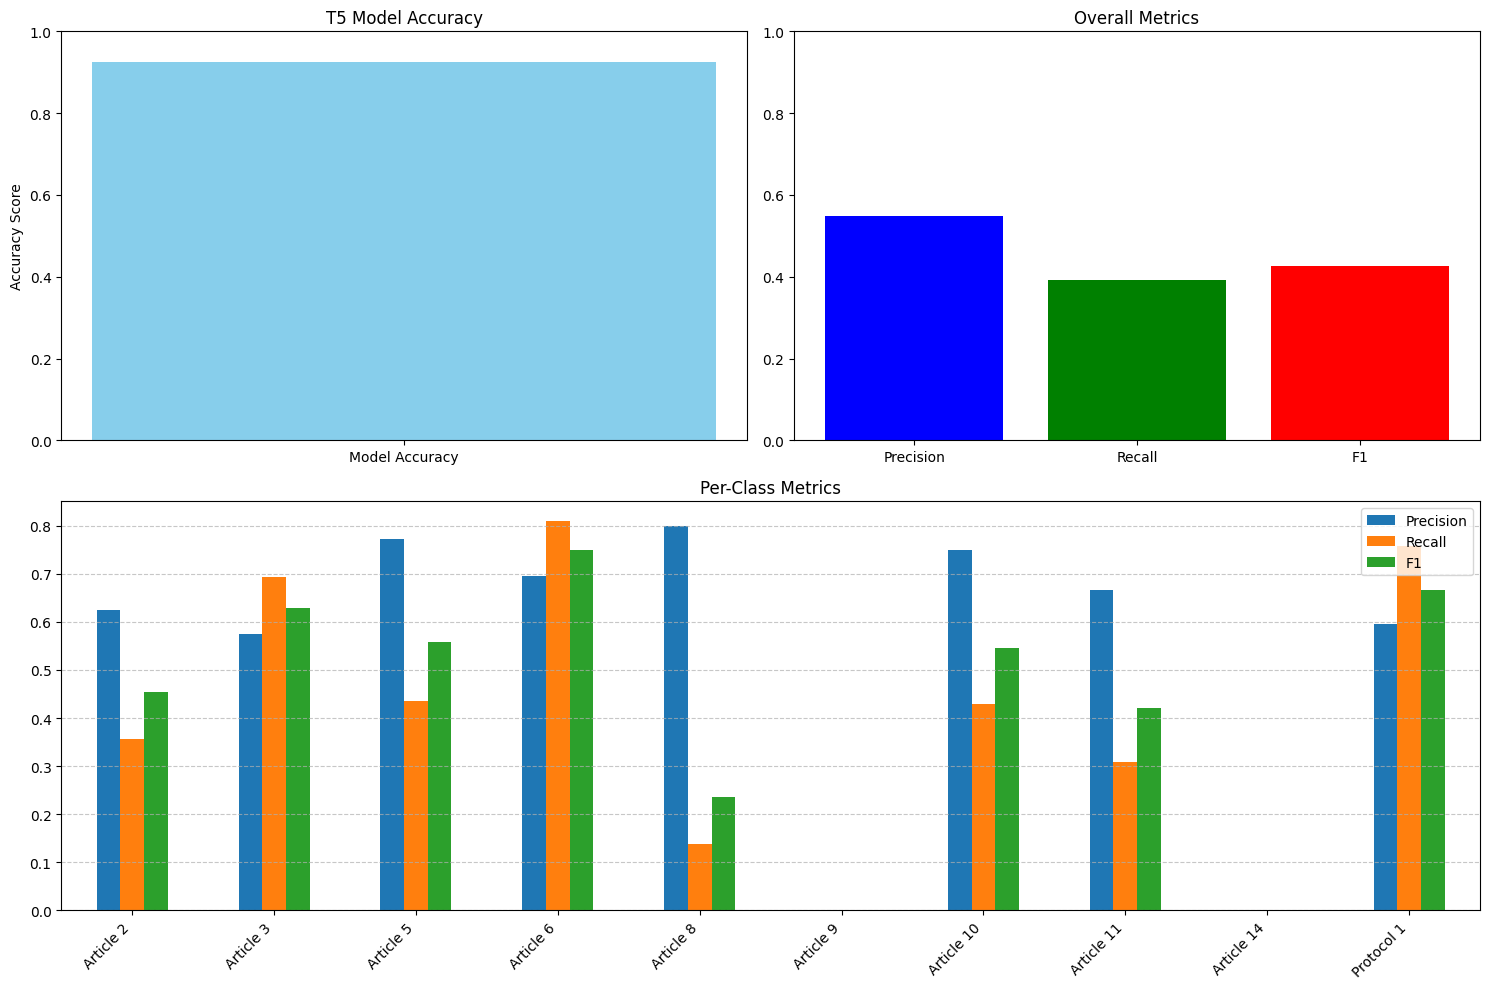


Evaluation complete. Results saved to CSV and plots saved as PNG.


In [ ]:
# Plotting Graphs
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.bar(['Model Accuracy'], [results['eval_accuracy']], color='skyblue')
plt.ylim(0, 1)
plt.title('T5 Model Accuracy')
plt.ylabel('Accuracy Score')

plt.subplot(2, 2, 2)
metrics = ['eval_precision', 'eval_recall', 'eval_f1']
plt.bar(range(len(metrics)), [results[m] for m in metrics], color=['blue', 'green', 'red'])
plt.xticks(range(len(metrics)), ['Precision', 'Recall', 'F1'])
plt.title('Overall Metrics')
plt.ylim(0, 1)

plt.subplot(2, 1, 2)
class_metrics = pd.DataFrame({
    'Precision': [report[name]['precision'] for name in article_names],
    'Recall': [report[name]['recall'] for name in article_names],
    'F1': [report[name]['f1-score'] for name in article_names]
})

class_metrics.plot(kind='bar', ax=plt.gca())
plt.title('Per-Class Metrics')
plt.xticks(range(len(article_names)), article_names, rotation=45, ha='right')
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('t5_model_evaluation.png', dpi=300)
plt.show()

report_df.to_csv('t5_classification_report.csv')
print("\nEvaluation complete. Results saved to CSV and plots saved as PNG.")